## 1. Build

Emissionsfactors from:
https://www.wettbewerb-energieeffizienz.de/WENEFF/Redaktion/DE/PDF-Anlagen-FW/informationsblatt-co2-faktoren-rili24-3-1.pdf?__blob=publicationFile&v=1

- Electricity ~ 0.435 kg_CO2/kWh
- Natural Gas ~ 0.201 kg_CO2/kWh

In [92]:
# Setup of the ES

import matplotlib.pyplot as plt
import pandas as pd

from oemof import solph
from oemof.solph import constraints, Investment

energysystem = solph.EnergySystem(
    timeindex=solph.create_time_index(year=2026,interval=1,number=24)
)
# factors
co2_ele = 0.435
co2_gas = 0.201 # natgas
co2_gas = 0.152

# Bus
## Gas
bus_gas = solph.Bus(label="Gas")
## Electro
bus_ele = solph.Bus(label="Electricity")
## Heat
bus_heat = solph.Bus(label="Heat")

energysystem.add(
    bus_gas,
    bus_ele,
    bus_heat,
)

# Sources
## PV
pv_profile = [ # -
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
    0.0, 0.0, 0.08403, 0.24741, 0.308595, 0.39654,
    0.414285, 0.36735, 0.273915, 0.156585, 0.00423, 0.0,
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0
]
pv_cap_max = 10 # kW
pv = solph.components.Source(
    label="PV",
    outputs={bus_ele: solph.Flow(
        nominal_capacity=Investment(
            maximum=pv_cap_max,
            ep_costs=1000/20/365,       # 1000 € / 20a / 365d
        ),
        maximum=pv_profile,

    )}
)

## grid electricity
grid_ele = solph.components.Source(
    label="grid_ele",
    outputs={bus_ele: solph.Flow(
        variable_costs=0.30,    # €/kWh
        custom_properties={"emission_factor": co2_ele},   # kg/kWh
    )}
)

## grid gas
grid_natgas = solph.components.Source(
    label="grid_natgas",
    outputs={bus_gas: solph.Flow(
        variable_costs=0.16,    # €/kWh
        custom_properties={"emission_factor": co2_gas},   # kg/kWh
    )}
)

energysystem.add(
    pv,
    grid_ele,
    grid_natgas
)
#

# DEMAND
##  excess
excess = solph.components.Sink(
    label="excess",
    inputs={
        bus_ele: solph.Flow()
    }
)

## demand electricity house
electricity_demand_profile = [ 0.3, 0.25, 0.2, 0.2, 0.25, 0.4, 0.6, 0.7, 0.5, 0.4, 0.35, 0.35, 0.4, 0.4, 0.4, 0.45, 0.6, 0.8, 1.0, 0.9, 0.8, 0.7, 0.5, 0.4 ]
demand_capacity = 4

electricity_demand = solph.components.Sink(
    label="electricity_demand",
    inputs={
        bus_ele: solph.Flow(
            nominal_capacity=demand_capacity,
            fix=electricity_demand_profile
        )
    }
)

## demand heat house
heat_demand_profile = [0.2, 0.3, 0.4, 0.4, 0.45, 0.35, 0.3, 0.25, 0.2, 0.1, 0.05, 0.1, 0.05, 0.05, 0.1, 0.05, 0.1, 0.15, 0.15, 0.1, 0.15, 0.20, 0.2, 0.2, 0.2]
heat_demand_capacity = 8
heat_demand = solph.components.Sink(
    label="heat_demand",
    inputs={
        bus_heat: solph.Flow(
            nominal_capacity=heat_demand_capacity,
            fix=heat_demand_profile
        )
    }
)

energysystem.add(
    excess,
    electricity_demand,
###    heat_demand
)
#

# CONVERT
to_invest = False
heater_cap = 10
## Gas Heizkessel
heater_efficiency = 0.95
if to_invest:
    heater_cap = Investment(
            maximum=heat_demand_capacity + 2,   # kW
            ep_costs=1000/20/365,
    )

heater_gas = solph.components.Converter(
    label="heater_gas",
    inputs={bus_gas: solph.Flow()},
    outputs={bus_heat: solph.Flow(
        nominal_capacity=heater_cap
        )},
    conversion_factors={bus_heat: heater_efficiency},
)

## heat pump
cop_fix = 1.7
if to_invest:
    heater_cap = Investment(
            maximum=heat_demand_capacity + 2,   # kW
            ep_costs=1000/20/365,
    )
heat_pump = solph.components.Converter(
    label="heat_pump",
    inputs={bus_ele: solph.Flow()},
    outputs={bus_heat: solph.Flow(
        nominal_capacity=heater_cap
    )},
    conversion_factors={bus_heat: cop_fix},
)

energysystem.add(
    heater_gas,
    heat_pump,
)
#



## 2. Visualize

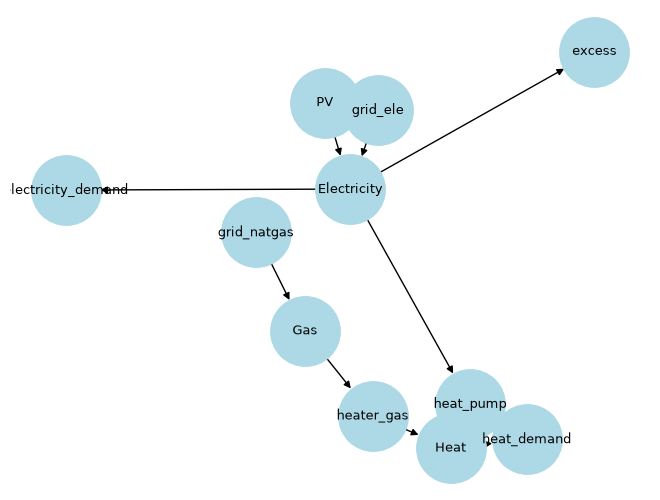

In [88]:
from helpers.visualize import plot_energy_system
plot_energy_system(energysystem)

## 3. Model + Add emission constraint

In [132]:
# init
model = solph.Model(energysystem)

# add emission constraint
constraints.emission_limit(model, limit=22)

# print out the emission constraint
model.integral_limit_emission_factor_upper_limit.pprint()
model.integral_limit_emission_factor.pprint()

integral_limit_emission_factor_upper_limit : Size=1, Index=None, Active=True
    Key  : Lower : Body                           : Upper : Active
    None :  -Inf : integral_limit_emission_factor :  22.0 :   True
integral_limit_emission_factor : Size=1, Index=None
    Key  : Expression
    None : 0.435*flow[grid_ele,Electricity,0] + 0.435*flow[grid_ele,Electricity,1] + 0.435*flow[grid_ele,Electricity,2] + 0.435*flow[grid_ele,Electricity,3] + 0.435*flow[grid_ele,Electricity,4] + 0.435*flow[grid_ele,Electricity,5] + 0.435*flow[grid_ele,Electricity,6] + 0.435*flow[grid_ele,Electricity,7] + 0.435*flow[grid_ele,Electricity,8] + 0.435*flow[grid_ele,Electricity,9] + 0.435*flow[grid_ele,Electricity,10] + 0.435*flow[grid_ele,Electricity,11] + 0.435*flow[grid_ele,Electricity,12] + 0.435*flow[grid_ele,Electricity,13] + 0.435*flow[grid_ele,Electricity,14] + 0.435*flow[grid_ele,Electricity,15] + 0.435*flow[grid_ele,Electricity,16] + 0.435*flow[grid_ele,Electricity,17] + 0.435*flow[grid_ele,Electricit

Well... manual approach:

## 4. Solve

In [133]:
results = model.solve()

print("Solved!")

Solved!


## 5. Plot Results

21.03763211275


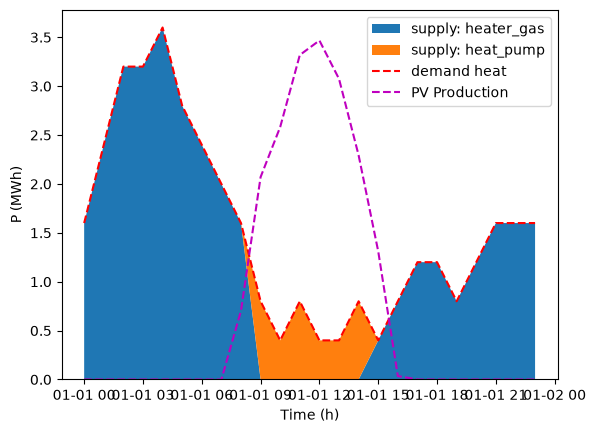

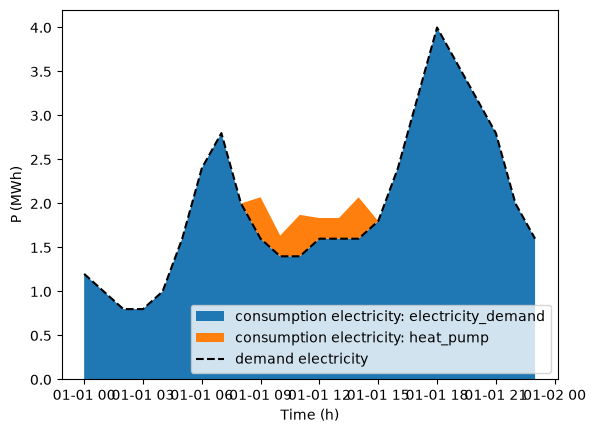

In [134]:
# print out the amount of emissions from the emission constraint
print(model.integral_limit_emission_factor())

# Gas Electricity Heat
## plot Heat
data = results["flow"]
outflows = data.xs("Heat", axis=1, level=0, drop_level=False)
inflows = data.xs("Heat", axis=1, level=1, drop_level=False)
pv_prod = data.xs("PV", axis=1, level=0, drop_level=False)

fig = plt.figure()
ax = fig.add_subplot()

ax.stackplot(
    inflows.index,
    inflows.T,
    labels=[f"supply: {col[0]}" for col in inflows.columns],
)
ax.plot(outflows, "r--", label="demand heat")
ax.plot(pv_prod, "m--", label="PV Production")

ax.legend()

ax.set_xlabel("Time (h)")
ax.set_ylabel("P (MWh)")
plt.show()

## plot ele
fig2 = plt.figure()
ax2 = fig2.add_subplot()
demand_ele = data.xs("Electricity", axis=1, level=0, drop_level=False)
demand_ele = demand_ele.drop("excess", axis=1, level=1)
demand_line = data.xs("electricity_demand", axis=1, level=1, drop_level=False)
ax2.stackplot(
    demand_ele.index,
    demand_ele.T,
    labels=[f"consumption electricity: {col[1]}" for col in demand_ele.columns],
)
ax2.plot(demand_line, "k--", label="demand electricity")
ax2.legend()
ax2.set_xlabel("Time (h)")
ax2.set_ylabel("P (MWh)")
plt.show()

# ax.plot(demand_ele, "k--", label="")



co2

                       grid_ele grid_natgas
                    Electricity         Gas
2026-01-01 00:00:00    0.522000       0.256
2026-01-01 01:00:00    0.435000       0.384
2026-01-01 02:00:00    0.348000       0.512
2026-01-01 03:00:00    0.348000       0.512
2026-01-01 04:00:00    0.435000       0.576
2026-01-01 05:00:00    0.696000       0.448
2026-01-01 06:00:00    1.044000       0.384
2026-01-01 07:00:00    1.218000       0.320
2026-01-01 08:00:00    0.564085       0.256
2026-01-01 09:00:00    0.000000       0.000
2026-01-01 10:00:00    0.000000       0.000
2026-01-01 11:00:00    0.000000       0.000
2026-01-01 12:00:00    0.000000       0.000
2026-01-01 13:00:00    0.000000       0.000
2026-01-01 14:00:00    0.000000       0.000
2026-01-01 15:00:00    0.212946       0.064
2026-01-01 16:00:00    1.028601       0.128
2026-01-01 17:00:00    1.392000       0.192
2026-01-01 18:00:00    1.740000       0.192
2026-01-01 19:00:00    1.566000       0.128
2026-01-01 20:00:00    1.392000 

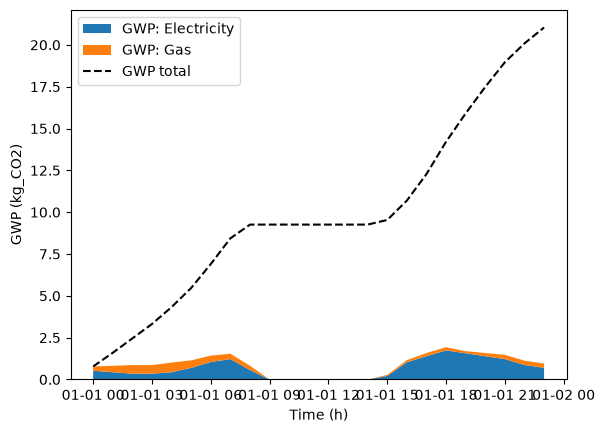

In [135]:
## plot co2
grid_consumption = data.loc[
    :, data.columns.get_level_values(0).isin(["grid_ele", "grid_natgas"])
].copy()

grid_consumption.loc[:, pd.IndexSlice["grid_ele", :]] *= co2_ele
grid_consumption.loc[:, pd.IndexSlice["grid_natgas", :]] *= co2_gas

print(grid_consumption)
fig3 = plt.figure()
ax3 = fig3.add_subplot()

ax3.stackplot(
    grid_consumption.index,
    grid_consumption.T,
    labels=[f"GWP: {col[1]}" for col in grid_consumption.columns],
)

# cumulate
grid_consumption_sum = grid_consumption.sum(axis=1)
grid_consumption_cum = grid_consumption_sum.cumsum()
ax3.plot(grid_consumption_cum, "k--", label="GWP total")


ax3.legend()
ax3.set_xlabel("Time (h)")
ax3.set_ylabel("GWP (kg_CO2)")
plt.show()